# 03 — Baseline OOF paired statistics

Compares VentiMorph v2.8.1 against the four reimplemented baselines on the exact same 80 OOF development patients.

This gives a matched development-set comparison complementary to the final locked-test comparison.

In [1]:

from pathlib import Path
import io
import json
import math
import shutil
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
EXPECTED_SPLIT_SHA256 = "d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459"

print("Python analysis environment ready.")


Python analysis environment ready.


In [2]:

def _json_load_bytes(raw):
    if isinstance(raw, bytes):
        raw = raw.decode("utf-8")
    return json.loads(raw)


def _bundle_candidates(metadata_filename, expected_model):
    """
    Finds a result bundle either as:
    1) a ZIP somewhere under /kaggle/input, or
    2) an already-extracted Kaggle dataset directory.
    """
    candidates = []

    # ZIP bundles.
    for zpath in INPUT_ROOT.rglob("*.zip"):
        try:
            with zipfile.ZipFile(zpath, "r") as zf:
                names = zf.namelist()
                if metadata_filename not in names:
                    continue
                meta = _json_load_bytes(zf.read(metadata_filename))
                if str(meta.get("model", "")) == expected_model:
                    candidates.append({
                        "kind": "zip",
                        "source": zpath,
                        "metadata": meta,
                        "metadata_filename": metadata_filename,
                    })
        except zipfile.BadZipFile:
            continue

    # Extracted bundles.
    for mpath in INPUT_ROOT.rglob(metadata_filename):
        try:
            meta = json.loads(mpath.read_text(encoding="utf-8"))
        except Exception:
            continue
        if str(meta.get("model", "")) == expected_model:
            candidates.append({
                "kind": "dir",
                "source": mpath.parent,
                "metadata": meta,
                "metadata_filename": metadata_filename,
            })

    if not candidates:
        raise FileNotFoundError(
            f"Could not find result bundle for model={expected_model!r}. "
            f"Attach the corresponding result ZIP to Kaggle."
        )

    # If the same bundle is attached more than once, choose the first
    # deterministic candidate and print a warning.
    candidates = sorted(candidates, key=lambda x: str(x["source"]))
    if len(candidates) > 1:
        print(
            f"Warning: found {len(candidates)} matching bundles for "
            f"{expected_model}; using {candidates[0]['source']}"
        )

    bundle = candidates[0]

    split_hash = bundle["metadata"].get("split_sha256")
    if split_hash is not None and split_hash != EXPECTED_SPLIT_SHA256:
        raise RuntimeError(
            f"Frozen split hash mismatch for {expected_model}: {split_hash}"
        )

    return bundle


def _read_csv_from_bundle(bundle, required_suffix):
    if bundle["kind"] == "zip":
        with zipfile.ZipFile(bundle["source"], "r") as zf:
            hits = [
                name for name in zf.namelist()
                if name.endswith(required_suffix)
            ]
            if len(hits) != 1:
                raise FileNotFoundError(
                    f"Expected exactly one *{required_suffix} inside "
                    f"{bundle['source']}, found {hits}"
                )
            return pd.read_csv(zf.open(hits[0]))

    hits = list(bundle["source"].rglob(f"*{required_suffix}"))
    if len(hits) != 1:
        raise FileNotFoundError(
            f"Expected exactly one *{required_suffix} under "
            f"{bundle['source']}, found {hits}"
        )
    return pd.read_csv(hits[0])


def _read_optional_csv_from_bundle(bundle, required_suffix):
    try:
        return _read_csv_from_bundle(bundle, required_suffix)
    except Exception:
        return None


def load_oof_model(expected_model):
    bundle = _bundle_candidates(
        "evaluation_metadata.json",
        expected_model,
    )
    df = _read_csv_from_bundle(bundle, "patient_metrics.csv").copy()

    if len(df) != 80 or df["patient_id"].nunique() != 80:
        raise RuntimeError(
            f"{expected_model}: expected 80 unique OOF patients, "
            f"found rows={len(df)}, unique={df['patient_id'].nunique()}."
        )

    if "fold" not in df.columns:
        raise RuntimeError(f"{expected_model}: OOF patient file has no fold column.")

    if bundle["metadata"].get("locked_test_evaluated") not in (False, None):
        raise RuntimeError(
            f"{expected_model}: OOF metadata says locked test was evaluated."
        )

    df["patient_id"] = df["patient_id"].astype(int)
    df = df.sort_values("patient_id").reset_index(drop=True)
    return bundle, df


def load_test_model(expected_model):
    bundle = _bundle_candidates(
        "final_locked_test_metadata.json",
        expected_model,
    )
    df = _read_csv_from_bundle(bundle, "patient_metrics.csv").copy()

    if len(df) != 20 or df["patient_id"].nunique() != 20:
        raise RuntimeError(
            f"{expected_model}: expected 20 unique locked-test patients, "
            f"found rows={len(df)}, unique={df['patient_id'].nunique()}."
        )

    df["patient_id"] = df["patient_id"].astype(int)
    df = df.sort_values("patient_id").reset_index(drop=True)
    return bundle, df


def assert_same_patients(reference_df, comparison_df, label):
    ref_ids = reference_df["patient_id"].astype(int).tolist()
    cmp_ids = comparison_df["patient_id"].astype(int).tolist()
    if ref_ids != cmp_ids:
        raise RuntimeError(
            f"Patient IDs/order do not match for {label}."
        )


def assert_same_oof_folds(reference_df, comparison_df, label):
    merged = reference_df[["patient_id", "fold"]].merge(
        comparison_df[["patient_id", "fold"]],
        on="patient_id",
        suffixes=("_reference", "_comparison"),
        validate="one_to_one",
    )
    if not np.array_equal(
        merged["fold_reference"].to_numpy(),
        merged["fold_comparison"].to_numpy(),
    ):
        raise RuntimeError(f"OOF fold assignments differ for {label}.")


In [3]:

METRICS = {
    "mean_foreground_dice": {
        "label": "Mean foreground Dice",
        "higher_is_better": True,
    },
    "ventricle_dice": {
        "label": "Ventricle Dice",
        "higher_is_better": True,
    },
    "normal_wmh_dice": {
        "label": "Normal-WMH Dice",
        "higher_is_better": True,
    },
    "abnormal_wmh_dice": {
        "label": "Abnormal-WMH Dice",
        "higher_is_better": True,
    },
    "normal_wmh_lesion_f1": {
        "label": "Normal-WMH lesion F1",
        "higher_is_better": True,
    },
    "abnormal_wmh_lesion_f1": {
        "label": "Abnormal-WMH lesion F1",
        "higher_is_better": True,
    },
    "periventricular_abnormal_fp_rate": {
        "label": "Periventricular abnormal FP rate",
        "higher_is_better": False,
    },
}


def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    adjusted_sorted = np.empty(n, dtype=float)

    running = 0.0
    for rank, idx in enumerate(order):
        value = (n - rank) * p[idx]
        running = max(running, value)
        adjusted_sorted[rank] = min(running, 1.0)

    adjusted = np.empty(n, dtype=float)
    for rank, idx in enumerate(order):
        adjusted[idx] = adjusted_sorted[rank]
    return adjusted


def paired_bootstrap_mean_ci(diff, repeats=20000, seed=42):
    diff = np.asarray(diff, dtype=float)
    diff = diff[np.isfinite(diff)]
    if len(diff) == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)
    idx = rng.integers(
        0,
        len(diff),
        size=(repeats, len(diff)),
        endpoint=False,
    )
    means = diff[idx].mean(axis=1)
    return (
        float(np.percentile(means, 2.5)),
        float(np.percentile(means, 97.5)),
    )


def rank_biserial_from_paired_difference(benefit_diff):
    """
    Matched-pairs rank-biserial correlation.
    Positive means the reference model is better.
    """
    d = np.asarray(benefit_diff, dtype=float)
    d = d[np.isfinite(d)]
    d = d[d != 0]

    if len(d) == 0:
        return 0.0

    ranks = stats.rankdata(np.abs(d), method="average")
    w_plus = float(ranks[d > 0].sum())
    w_minus = float(ranks[d < 0].sum())
    denom = w_plus + w_minus
    return 0.0 if denom == 0 else (w_plus - w_minus) / denom


def cohen_dz(benefit_diff):
    d = np.asarray(benefit_diff, dtype=float)
    d = d[np.isfinite(d)]
    if len(d) < 2:
        return np.nan
    sd = d.std(ddof=1)
    if sd == 0:
        return np.nan
    return float(d.mean() / sd)


def paired_comparison_rows(
    reference_df,
    comparison_df,
    reference_name,
    comparison_name,
    bootstrap_repeats=20000,
    seed=42,
):
    assert_same_patients(reference_df, comparison_df, comparison_name)

    rows = []

    for metric, info in METRICS.items():
        ref = pd.to_numeric(reference_df[metric], errors="coerce").to_numpy(float)
        cmp = pd.to_numeric(comparison_df[metric], errors="coerce").to_numpy(float)

        finite = np.isfinite(ref) & np.isfinite(cmp)
        ref = ref[finite]
        cmp = cmp[finite]

        raw_diff = ref - cmp
        benefit_diff = raw_diff if info["higher_is_better"] else -raw_diff

        if len(benefit_diff) == 0:
            continue

        # Wilcoxon signed-rank is pre-specified for paired patient-level comparison.
        try:
            wilcoxon = stats.wilcoxon(
                benefit_diff,
                alternative="two-sided",
                zero_method="wilcox",
                method="auto",
            )
            p_value = float(wilcoxon.pvalue)
            statistic = float(wilcoxon.statistic)
        except ValueError:
            p_value = 1.0
            statistic = 0.0

        ci_low, ci_high = paired_bootstrap_mean_ci(
            benefit_diff,
            repeats=bootstrap_repeats,
            seed=seed,
        )

        wins = int(np.sum(benefit_diff > 0))
        ties = int(np.sum(benefit_diff == 0))
        losses = int(np.sum(benefit_diff < 0))

        rows.append({
            "reference_model": reference_name,
            "comparison_model": comparison_name,
            "metric": metric,
            "metric_label": info["label"],
            "higher_is_better": info["higher_is_better"],
            "n_paired": int(len(benefit_diff)),
            "reference_mean": float(np.mean(ref)),
            "comparison_mean": float(np.mean(cmp)),
            "raw_mean_difference_reference_minus_comparison": float(np.mean(raw_diff)),
            "benefit_mean_difference_positive_favors_reference": float(np.mean(benefit_diff)),
            "benefit_bootstrap_95ci_low": ci_low,
            "benefit_bootstrap_95ci_high": ci_high,
            "wilcoxon_statistic": statistic,
            "wilcoxon_p_raw": p_value,
            "rank_biserial_positive_favors_reference": float(
                rank_biserial_from_paired_difference(benefit_diff)
            ),
            "cohen_dz_positive_favors_reference": cohen_dz(benefit_diff),
            "reference_wins": wins,
            "ties": ties,
            "comparison_wins": losses,
        })

    return pd.DataFrame(rows)


def add_holm_by_metric(stats_df):
    out = stats_df.copy()
    out["wilcoxon_p_holm"] = np.nan

    for metric, idx in out.groupby("metric").groups.items():
        idx = list(idx)
        out.loc[idx, "wilcoxon_p_holm"] = holm_adjust(
            out.loc[idx, "wilcoxon_p_raw"].to_numpy(float)
        )

    out["significant_holm_0_05"] = out["wilcoxon_p_holm"] < 0.05
    return out


def model_summary_table(model_frames, metric_names=None):
    if metric_names is None:
        metric_names = list(METRICS.keys())

    rows = []
    for model_name, df in model_frames.items():
        row = {"model": model_name, "n_patients": int(len(df))}
        for metric in metric_names:
            values = pd.to_numeric(df[metric], errors="coerce").to_numpy(float)
            values = values[np.isfinite(values)]
            row[f"{metric}_mean"] = float(np.mean(values))
            row[f"{metric}_sd"] = float(np.std(values, ddof=1)) if len(values) > 1 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


In [4]:

MODEL_IDS = {
    "VentiMorph v2.8.1": "VentiMorph-RelNet-v2.8.1-segmentation-first",
    "FCN-8s": "FCN-8s",
    "SegNet": "SegNet",
    "U-Net": "U-Net",
    "U-Net++": "Reimplemented U-Net++ baseline under common protocol",
}

bundles = {}
frames = {}

for display_name, metadata_model in MODEL_IDS.items():
    bundle, frame = load_oof_model(metadata_model)
    bundles[display_name] = bundle
    frames[display_name] = frame
    print(display_name, "->", bundle["source"], "| patients:", len(frame))

reference = frames["VentiMorph v2.8.1"]

for model_name, frame in frames.items():
    assert_same_patients(reference, frame, model_name)
    assert_same_oof_folds(reference, frame, model_name)

print("\nAll five OOF models use the same 80 patients and identical fold assignments.")


VentiMorph v2.8.1 -> /kaggle/input/datasets/saifsamiul/ms3seg-final-analysis-inputs/MS3SEG_V281_5FOLD_OOF_VALIDATION_RESULTS | patients: 80
FCN-8s -> /kaggle/input/datasets/saifsamiul/ms3seg-final-analysis-inputs/MS3SEG_FCN8S_5FOLD_OOF_VALIDATION_RESULTS | patients: 80
SegNet -> /kaggle/input/datasets/saifsamiul/ms3seg-final-analysis-inputs/MS3SEG_SEGNET_5FOLD_OOF_VALIDATION_RESULTS | patients: 80
U-Net -> /kaggle/input/datasets/saifsamiul/ms3seg-final-analysis-inputs/MS3SEG_UNET_5FOLD_OOF_VALIDATION_RESULTS | patients: 80
U-Net++ -> /kaggle/input/datasets/saifsamiul/ms3seg-final-analysis-inputs/MS3SEG_UNETPP_5FOLD_OOF_VALIDATION_RESULTS | patients: 80

All five OOF models use the same 80 patients and identical fold assignments.


In [5]:

OUTPUT_DIR = WORK_ROOT / "baseline_oof_paired_statistics"
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

all_stats = []
for model_name in ["FCN-8s", "SegNet", "U-Net", "U-Net++"]:
    result = paired_comparison_rows(
        frames["VentiMorph v2.8.1"],
        frames[model_name],
        reference_name="VentiMorph v2.8.1",
        comparison_name=model_name,
        bootstrap_repeats=20000,
        seed=42,
    )
    all_stats.append(result)

stats_df = add_holm_by_metric(pd.concat(all_stats, ignore_index=True))
summary_df = model_summary_table(frames)

stats_df.to_csv(
    OUTPUT_DIR / "baseline_oof_paired_statistics_all_metrics.csv",
    index=False,
)
summary_df.to_csv(
    OUTPUT_DIR / "baseline_oof_model_summary.csv",
    index=False,
)

primary_df = stats_df[
    stats_df["metric"] == "mean_foreground_dice"
].copy()
primary_df.to_csv(
    OUTPUT_DIR / "baseline_oof_primary_mean_fg_dice_statistics.csv",
    index=False,
)

display(summary_df)
display(primary_df)


,model,n_patients,mean_foreground_dice_mean,mean_foreground_dice_sd,ventricle_dice_mean,ventricle_dice_sd,normal_wmh_dice_mean,normal_wmh_dice_sd,abnormal_wmh_dice_mean,abnormal_wmh_dice_sd,normal_wmh_lesion_f1_mean,normal_wmh_lesion_f1_sd,abnormal_wmh_lesion_f1_mean,abnormal_wmh_lesion_f1_sd,periventricular_abnormal_fp_rate_mean,periventricular_abnormal_fp_rate_sd
0,VentiMorph v2.8.1,80,0.806272,0.036189,0.912787,0.017724,0.714956,0.060540,0.791074,0.083359,0.574617,0.096715,0.751757,0.106026,0.230310,0.138505
1,FCN-8s,80,0.595043,0.049259,0.780442,0.044684,0.436313,0.057693,0.568376,0.108720,0.363303,0.086512,0.555939,0.136050,0.471888,0.144537
2,SegNet,80,0.664045,0.042609,0.842618,0.031782,0.512226,0.058119,0.637292,0.104838,0.381025,0.068805,0.574600,0.120349,0.375107,0.171034
3,U-Net,80,0.786635,0.041887,0.901038,0.018591,0.690461,0.060620,0.768405,0.097004,0.549174,0.099807,0.723601,0.112870,0.234424,0.142148
4,U-Net++,80,0.797105,0.036175,0.904333,0.020486,0.705568,0.062379,0.781415,0.077540,0.572911,0.093774,0.729139,0.109870,0.233683,0.154688


,reference_model,comparison_model,metric,metric_label,higher_is_better,n_paired,reference_mean,comparison_mean,raw_mean_difference_reference_minus_comparison,benefit_mean_difference_positive_favors_reference,...,benefit_bootstrap_95ci_high,wilcoxon_statistic,wilcoxon_p_raw,rank_biserial_positive_favors_reference,cohen_dz_positive_favors_reference,reference_wins,ties,comparison_wins,wilcoxon_p_holm,significant_holm_0_05
0,VentiMorph v2.8.1,FCN-8s,mean_foreground_dice,Mean foreground Dice,True,80,0.806272,0.595043,0.211229,0.211229,...,0.218779,0.0,7.849527e-15,1.000000,6.201666,80,0,0,3.139811e-14,True
7,VentiMorph v2.8.1,SegNet,mean_foreground_dice,Mean foreground Dice,True,80,0.806272,0.664045,0.142227,0.142227,...,0.147803,0.0,7.849527e-15,1.000000,5.530109,80,0,0,3.139811e-14,True
14,VentiMorph v2.8.1,U-Net,mean_foreground_dice,Mean foreground Dice,True,80,0.806272,0.786635,0.019638,0.019638,...,0.024892,285.0,1.523099e-10,0.824074,0.843761,72,0,8,3.046197e-10,True
21,VentiMorph v2.8.1,U-Net++,mean_foreground_dice,Mean foreground Dice,True,80,0.806272,0.797105,0.009167,0.009167,...,0.013021,581.0,6.249522e-07,0.641358,0.503631,63,0,17,6.249522e-07,True


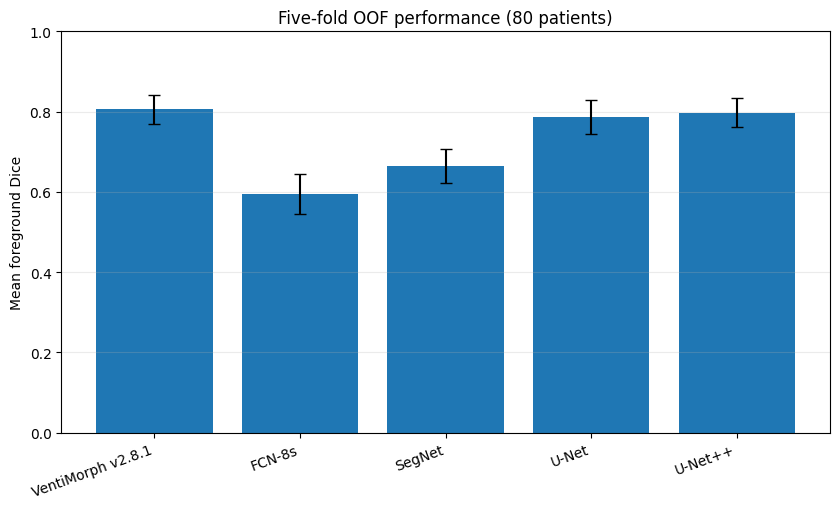

In [6]:

plot_df = pd.DataFrame({
    "model": list(frames.keys()),
    "mean": [
        frames[m]["mean_foreground_dice"].mean()
        for m in frames
    ],
    "sd": [
        frames[m]["mean_foreground_dice"].std(ddof=1)
        for m in frames
    ],
})

fig, ax = plt.subplots(figsize=(8.5, 5.2))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["mean"], yerr=plot_df["sd"], capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(plot_df["model"], rotation=20, ha="right")
ax.set_ylabel("Mean foreground Dice")
ax.set_title("Five-fold OOF performance (80 patients)")
ax.set_ylim(0, 1.0)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "Figure_baseline_oof_mean_fg_dice.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "Figure_baseline_oof_mean_fg_dice.pdf",
    bbox_inches="tight",
)
plt.show()


In [7]:

archive = shutil.make_archive(
    "/kaggle/working/MS3SEG_BASELINE_OOF_PAIRED_STATISTICS_RESULTS",
    "zip",
    root_dir=OUTPUT_DIR,
)
print("Download:", archive)


Download: /kaggle/working/MS3SEG_BASELINE_OOF_PAIRED_STATISTICS_RESULTS.zip
